set up for our directory to ensure all files are saved and ran correctly.


In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seed = 42
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
DATA_DIR, RESULTS_DIR, FIGURES_DIR = ROOT / "data", ROOT / "results", ROOT / "figures"
for d in (DATA_DIR, RESULTS_DIR, FIGURES_DIR):
    d.mkdir(exist_ok=True)

get our cleaned data frame.
If not in the repo run cleanData.ipynb

In [26]:
cleaned_df = pd.read_csv(DATA_DIR / "cleaned_data_sample.csv")

import sklearn and set up our variables.

Additionally split our data sample into training and test data 80% and 20%.

In [27]:
import sklearn as sk
from sklearn import model_selection


x = cleaned_df["review_text"]
y = cleaned_df["review_score"]

#Split into training 80% and testing 20%
x_train, x_test, y_train, y_test = model_selection.train_test_split(x, y, test_size = 0.2, random_state = seed, stratify = y)

Vectorize our review text, so it can be read.

In [11]:
fit_transformer = sk.feature_extraction.text.TfidfVectorizer()


x_train_tfidf = fit_transformer.fit_transform(x_train)
x_test_tfidf = fit_transformer.transform(x_test)

In [12]:
print(x_train_tfidf.shape)
print(x_test_tfidf.shape)

(154993, 106567)
(38749, 106567)


Now check and make sure we are close to 82% 18% split. 

In [13]:
print(pd.Series(y_train).value_counts(normalize=True))
print(pd.Series(y_test).value_counts(normalize=True))

review_score
 1    0.821986
-1    0.178014
Name: proportion, dtype: float64
review_score
 1    0.821983
-1    0.178017
Name: proportion, dtype: float64


Get a basline model and predictions set up, will be used for scoring later.

We use the most frequent strategy for our baseline due to the class imbalance of our data set with the 82/18 split.

In [14]:
import sklearn.dummy as dm#imports needed for a baseline model
from sklearn import metrics

baseline_model = dm.DummyClassifier(strategy = "most_frequent")
baseline_model.fit(x_train_tfidf, y_train) #learns the most frequent class from the training data

baseline_predictions =baseline_model.predict(x_test_tfidf)

Set up baseline confusion matrix and accuracy, that will be used for comparsion later.

In [15]:
baseline_accuracy = metrics.accuracy_score(y_test, baseline_predictions)
baseline_confusion_matrix = metrics.confusion_matrix(y_test, baseline_predictions)
baseline_classification_report = metrics.classification_report(y_test, baseline_predictions)

print("Baseline Model Accuracy:", baseline_accuracy)
print("Baseline Model Confusion Matrix:\n", baseline_confusion_matrix)
print("Baseline Model Classification Report:\n", baseline_classification_report)


Baseline Model Accuracy: 0.8219825027742651
Baseline Model Confusion Matrix:
 [[    0  6898]
 [    0 31851]]
Baseline Model Classification Report:
               precision    recall  f1-score   support

          -1       0.00      0.00      0.00      6898
           1       0.82      1.00      0.90     31851

    accuracy                           0.82     38749
   macro avg       0.41      0.50      0.45     38749
weighted avg       0.68      0.82      0.74     38749



c:\Users\ajdab\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ajdab\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ajdab\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

Set up our logisticalRegression Model, best for text, and get same metrics for comparsion i.e accuracy, confusion matrix, etc.

In [16]:
from sklearn import linear_model as lm

#To options here that I can use, balanced or None. There is a tradeoff between these two that I will mention later.
lr_model = lm.LogisticRegression(max_iter = 1000, class_weight = "balanced", random_state = seed)

lr_model.fit(x_train_tfidf, y_train)
lr_predictions = lr_model.predict(x_test_tfidf)

#Score our model the same way we scored baseline
lr_accuracy = metrics.accuracy_score(y_test, lr_predictions)
lr_confusion_matrix = metrics.confusion_matrix(y_test, lr_predictions)
lr_classification_report = metrics.classification_report(y_test, lr_predictions)


print("Logistic Regression Model Accuracy:", lr_accuracy)
print("Logistic Regression Model Confusion Matrix:\n", lr_confusion_matrix)
print("Logistic Regression Model Classification Report:\n", lr_classification_report)

Logistic Regression Model Accuracy: 0.8638416475263878
Logistic Regression Model Confusion Matrix:
 [[ 5763  1135]
 [ 4141 27710]]
Logistic Regression Model Classification Report:
               precision    recall  f1-score   support

          -1       0.58      0.84      0.69      6898
           1       0.96      0.87      0.91     31851

    accuracy                           0.86     38749
   macro avg       0.77      0.85      0.80     38749
weighted avg       0.89      0.86      0.87     38749



In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score

lr_neg_precision = precision_score(y_test, lr_predictions, pos_label=-1)
lr_neg_recall    = recall_score(y_test, lr_predictions, pos_label=-1)
lr_neg_f1        = f1_score(y_test, lr_predictions, pos_label=-1)

print("Negative class precision:", lr_neg_precision)
print("Negative class recall:   ", lr_neg_recall)
print("Negative class F1:       ", lr_neg_f1)

Negative class precision: 0.5818861066235864
Negative class recall:    0.8354595534937663
Negative class F1:        0.6859897631234377


Decided on balanced weights as the main goal is to find the negative reviews and the common theme among them. Therefor missing negatives is much more costly.

Now we will work on a tree-based model. Note this will be more difficult due to the features and the amount of the features.

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

#Want to limit features to 10K and ignore words that appear in less than 5 reviews.
#Additionally, only use unigrams single words, and not pairs.
tfidf_cap = TfidfVectorizer(max_features=10000, min_df=5, ngram_range=(1, 1))
x_train_cap = tfidf_cap.fit_transform(x_train)   # learn vocabulary from TRAIN only
x_test_cap = tfidf_cap.transform(x_test)         # apply it to test
print(x_train_cap.shape, x_test_cap.shape)

(154993, 10000) (38749, 10000)


Set up our baseline and logisticRegression model the same as before but with the limited features to make comparsion fair. 

In [19]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

baseline = DummyClassifier(strategy="most_frequent").fit(x_train_cap, y_train)
lr_plain = LogisticRegression(max_iter=1000, random_state=seed).fit(x_train_cap, y_train)
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=seed).fit(x_train_cap, y_train)

our tree-based model random forest with the same limited feautures.

In [20]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=seed,
)
rf_model.fit(x_train_cap, y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consid

Scoring and comparing all of our different models.

In [21]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

def score_model(name, model, X, y_true):
    pred = model.predict(X)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, pred),
        "neg_precision": precision_score(y_true, pred, pos_label=-1, zero_division=0),
        "neg_recall": recall_score(y_true, pred, pos_label=-1),
        "neg_f1": f1_score(y_true, pred, pos_label=-1),
        "roc_auc": roc_auc_score(y_true, model.predict_proba(X)[:, 1]),
    }

results = pd.DataFrame([
    score_model("Baseline (most frequent)", baseline, x_test_cap, y_test),
    score_model("Logistic regression", lr_plain, x_test_cap, y_test),
    score_model("Logistic regression (balanced)", lr_bal, x_test_cap, y_test),
    score_model("Random forest (balanced)", rf_model, x_test_cap, y_test),
]).round(3)

results.to_csv(RESULTS_DIR / "results_table.csv", index=False)
print(results)

                            model  accuracy  neg_precision  neg_recall  \
0        Baseline (most frequent)     0.822          0.000       0.000   
1             Logistic regression     0.897          0.787       0.575   
2  Logistic regression (balanced)     0.860          0.572       0.842   
3        Random forest (balanced)     0.873          0.694       0.508   

   neg_f1  roc_auc  
0   0.000    0.500  
1   0.664    0.929  
2   0.681    0.929  
3   0.587    0.899  


Set up and display confusion matrix for easy display comparsion on models.

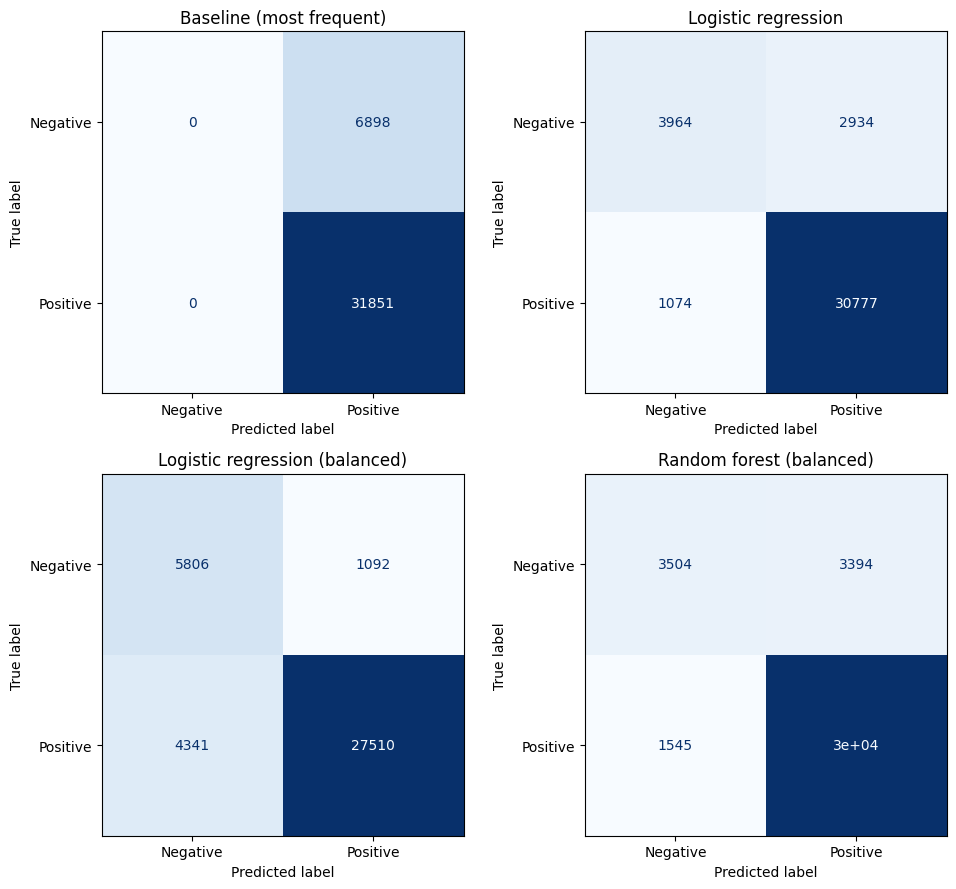

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
panels = [("Baseline (most frequent)", baseline), ("Logistic regression", lr_plain),
          ("Logistic regression (balanced)", lr_bal), ("Random forest (balanced)", rf_model)]
for ax, (title, model) in zip(axes.ravel(), panels):
    ConfusionMatrixDisplay.from_estimator(
        model, x_test_cap, y_test, labels=[-1, 1],
        display_labels=["Negative", "Positive"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig1_confusion_matrices.png", dpi=200)
plt.show()

Note cant include baseline because it ignores negatives entirely.

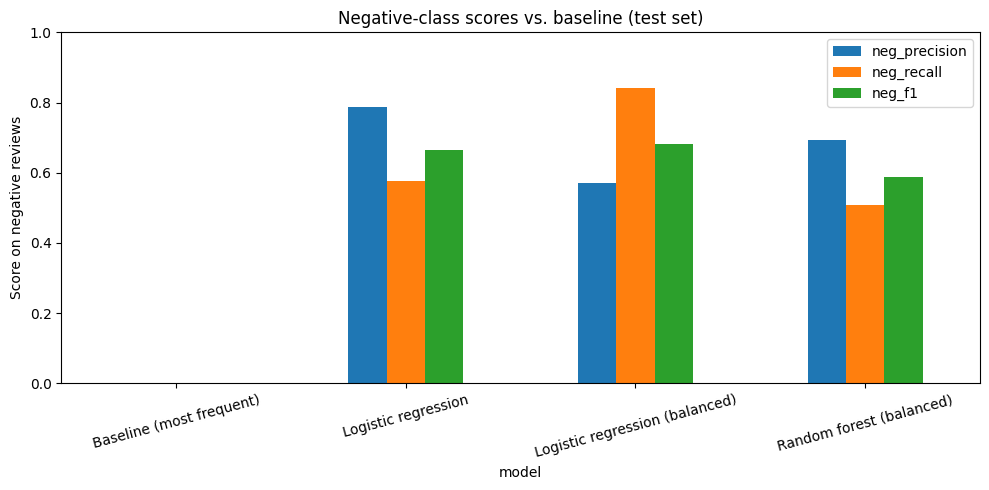

In [23]:
# AI-generated (Claude), reviewed by me
ax = results.set_index("model")[["neg_precision", "neg_recall", "neg_f1"]].plot.bar(figsize=(10, 5), rot=15)
ax.set_ylabel("Score on negative reviews")
ax.set_ylim(0, 1)
ax.set_title("Negative-class scores vs. baseline (test set)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig1b_negative_class_scores.png", dpi=200)
plt.show()

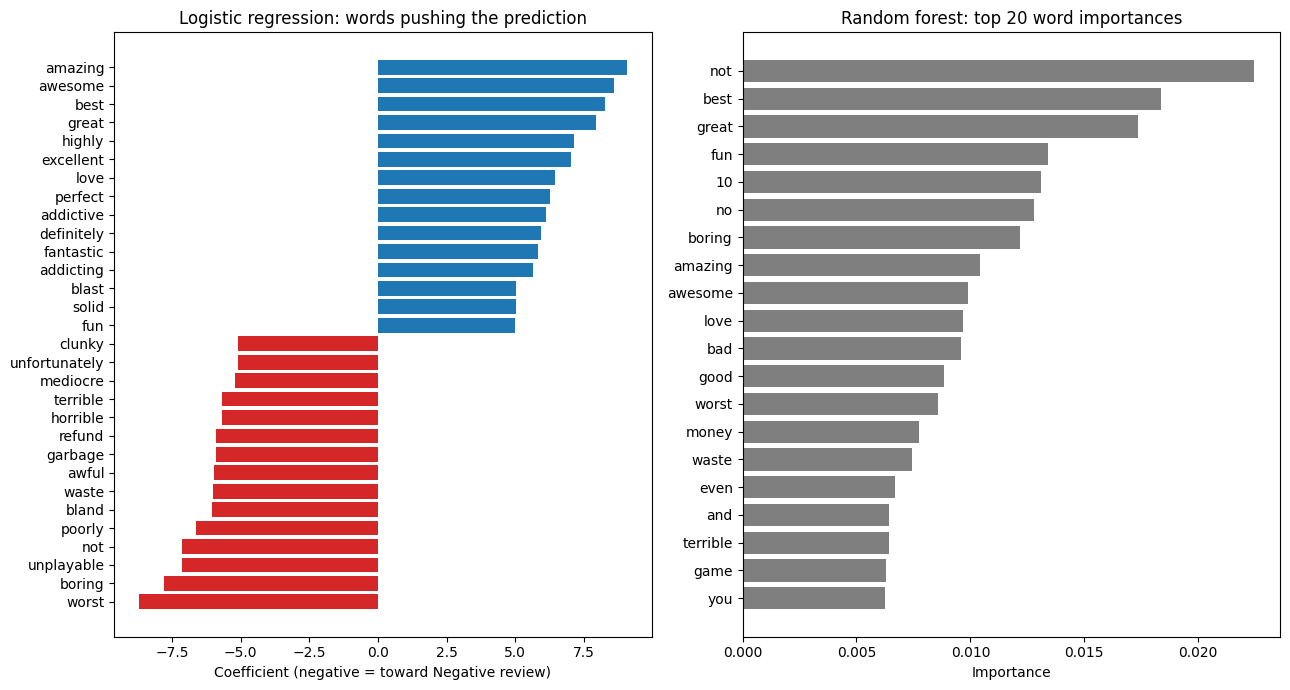

In [ ]:
import numpy as np

words = np.array(tfidf_cap.get_feature_names_out())

#Logistic regression coefficients. Classes are [-1, 1], so positive = pushes toward "positive review"
coefs = lr_bal.coef_[0]
order = np.argsort(coefs)
idx = np.concatenate([order[:15], order[-15:]])      #15 most negative + 15 most positive
colors = ["tab:red" if c < 0 else "tab:blue" for c in coefs[idx]]

#Random forest: importance scores
imp = rf_model.feature_importances_
top = np.argsort(imp)[-20:]

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
axes[0].barh(words[idx], coefs[idx], color=colors)
axes[0].set_title("Logistic regression: words pushing the prediction")
axes[0].set_xlabel("Coefficient (negative = toward Negative review)")
axes[1].barh(words[top], imp[top], color="tab:gray")
axes[1].set_title("Random forest: top 20 word importances")
axes[1].set_xlabel("Importance")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig2_feature_reliance.png", dpi=200)
plt.show()

In [ ]:
#Ai-generated code revied by author: Aramis Hernandez

from sklearn.model_selection import train_test_split

x_fit, x_val, y_fit, y_val = train_test_split(
    x_train_cap, y_train, test_size=0.2, random_state=seed, stratify=y_train)

rf_kwargs = dict(n_estimators=100, class_weight="balanced_subsample", n_jobs=-1, random_state=seed)
candidates = {
    "LR unweighted": LogisticRegression(max_iter=1000, random_state=seed),
    "LR balanced": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=seed),
    "RF leaf=2": RandomForestClassifier(min_samples_leaf=2, **rf_kwargs),
    "RF leaf=5": RandomForestClassifier(min_samples_leaf=5, **rf_kwargs),
}

rows = []
for name, model in candidates.items():
    model.fit(x_fit, y_fit)
    pred = model.predict(x_val)
    rows.append({"setting": name,
                 "neg_precision": precision_score(y_val, pred, pos_label=-1, zero_division=0),
                 "neg_recall": recall_score(y_val, pred, pos_label=-1),
                 "neg_f1": f1_score(y_val, pred, pos_label=-1)})

val_results = pd.DataFrame(rows).round(3)
val_results.to_csv(RESULTS_DIR / "validation_results.csv", index=False)
print(val_results)

         setting  neg_precision  neg_recall  neg_f1
0  LR unweighted          0.810       0.557   0.660
1    LR balanced          0.583       0.848   0.691
2      RF leaf=2          0.710       0.503   0.589
3      RF leaf=5          0.628       0.683   0.654
